# Master equation and continuum limit

The discrete master equation redistributes probability between nearest
neighbors. Holding $D=\ell^2/(2\Delta t)$ fixed while refining the walk
produces the Gaussian diffusion kernel.

The numerical calculation, verification, and plotting are kept in separate
cells. Plotting cells only read stored results and do not advance the model or
generate new random samples.


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "README.md").exists()
    and (
        (path / "main.tex").exists()
        or (path / "lecture-notes" / "main.tex").exists()
    )
)
if ROOT.name == "dlsu_PHY627M_GS1":
    OUTPUT = ROOT / "figures" / "24_brownian-motion-diffusion"
elif ROOT.name == "dlsu_SEMPHY01":
    OUTPUT = ROOT / "lecture-notes" / "figures" / "08_brownian-motion-diffusion"
else:
    raise RuntimeError(f"unsupported course repository: {ROOT}")
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})


## Probability recursion

The final physical time and diffusivity are fixed. Each refinement changes both
the step duration and lattice spacing. The probability mass is evolved by the
nearest-neighbor master equation.


In [2]:
final_time = 1.0
diffusivity = 0.50
step_counts = np.array([16, 64, 256, 1024])
solutions = []
errors = []

for step_count in step_counts:
    time_step = final_time / step_count
    step_length = np.sqrt(2.0 * diffusivity * time_step)
    probability = np.array([1.0])
    for _ in range(step_count):
        updated = np.zeros(probability.size + 2)
        updated[:-2] += 0.5 * probability
        updated[2:] += 0.5 * probability
        probability = updated

    site_index = np.arange(-step_count, step_count + 1)
    reachable = (site_index + step_count) % 2 == 0
    coordinate = site_index[reachable] * step_length
    mass = probability[reachable]
    reachable_spacing = 2.0 * step_length
    density = mass / reachable_spacing
    theory = np.exp(-coordinate**2 / (4.0 * diffusivity * final_time)) / np.sqrt(
        4.0 * np.pi * diffusivity * final_time
    )
    error = np.sum(np.abs(density - theory)) * reachable_spacing
    errors.append(error)
    solutions.append((coordinate, density, theory, mass))


## Verification

Every discrete distribution remains normalized. The integrated density error
must decrease under refinement.


In [3]:
for _, _, _, mass in solutions:
    assert np.isclose(np.sum(mass), 1.0, atol=1.0e-14)
assert np.all(np.diff(errors) < 0.0)
convergence_order = np.polyfit(
    np.log(step_counts), np.log(errors), 1
)[0]
print("integrated errors:", np.array(errors))
print(f"error exponent versus N = {convergence_order:.4f}")


integrated errors: [0.01547892 0.0036184  0.00091069 0.00022793]
error exponent versus N = -1.0123


## Instructive plot

Three panels show the discrete mass density approaching the diffusion kernel.
The final panel quantifies convergence rather than relying on visual agreement.


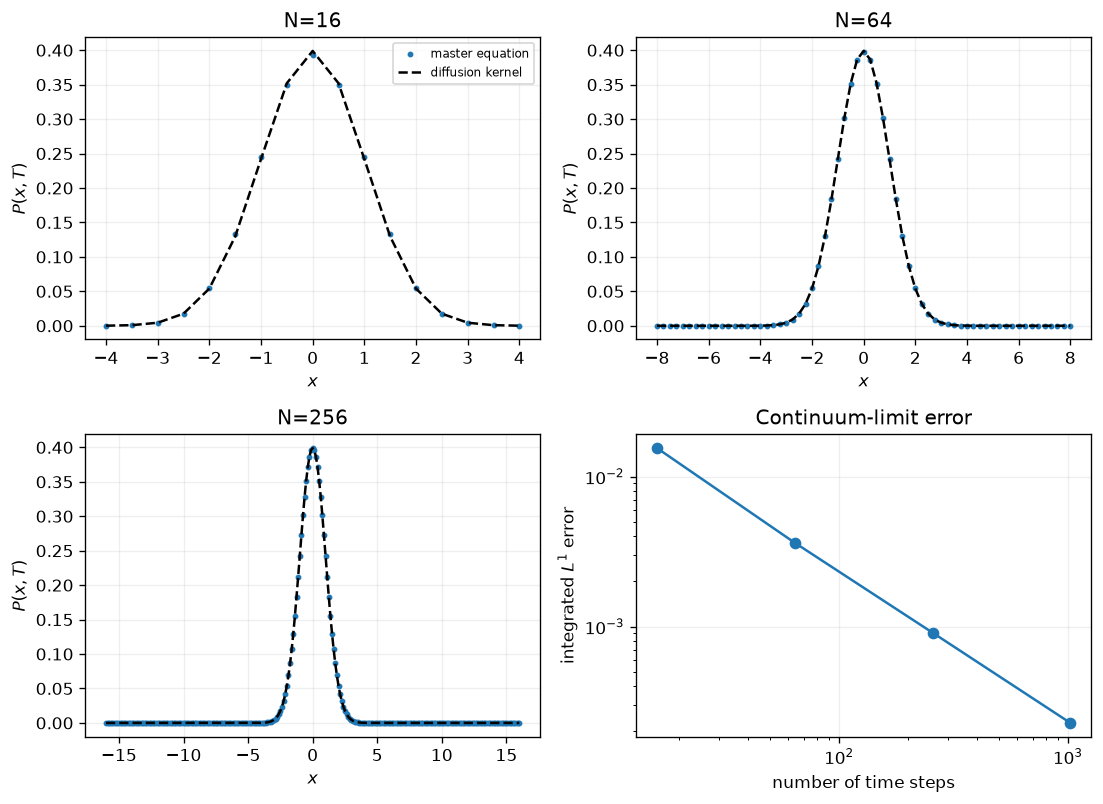

wrote lecture-notes/figures/08_brownian-motion-diffusion/08-master-equation-continuum-limit.pdf


In [4]:
figure, axes = plt.subplots(2, 2, figsize=(9.2, 6.8))

for axis, solution, step_count in zip(
    axes.flat[:3], solutions[:3], step_counts[:3], strict=True
):
    coordinate, density, theory, _ = solution
    axis.plot(coordinate, density, "o", markersize=2.5, label="master equation")
    axis.plot(coordinate, theory, "k--", label="diffusion kernel")
    axis.set(title=f"N={step_count}", xlabel=r"$x$", ylabel=r"$P(x,T)$")
    axis.grid(alpha=0.2)
axes[0, 0].legend(fontsize=7)

axes[1, 1].loglog(step_counts, errors, "o-")
axes[1, 1].set(
    title="Continuum-limit error",
    xlabel="number of time steps",
    ylabel=r"integrated $L^1$ error",
)
axes[1, 1].grid(alpha=0.2)
figure.tight_layout()
output_path = OUTPUT / "08-master-equation-continuum-limit.pdf"
figure.savefig(
    output_path,
    bbox_inches="tight",
    metadata={"Creator": f"DLSU {ROOT.name.removeprefix('dlsu_')}", "CreationDate": None, "ModDate": None},
)
plt.show()
print(f"wrote {output_path.relative_to(ROOT)}")
